<a href="https://colab.research.google.com/github/ferelsimanjorag/Rock-Fracture-Analysis/blob/main/Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

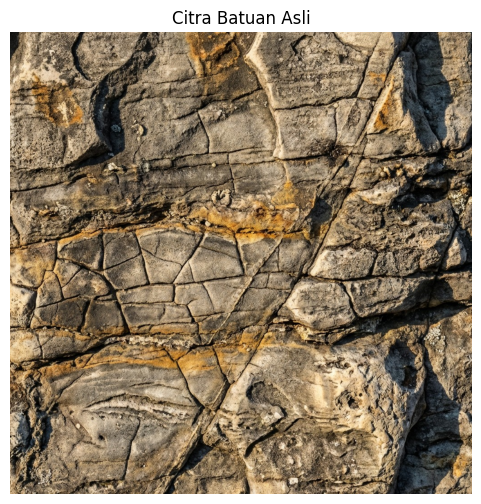

In [1]:
import cv2
import matplotlib.pyplot as plt

# 1. Membaca gambar dari ruang penyimpanan Colab
gambar_asli = cv2.imread('batu1.jpg')

# 2. Mengubah urutan warna dari BGR (bawaan OpenCV) ke RGB (warna normal manusia)
gambar_rgb = cv2.cvtColor(gambar_asli, cv2.COLOR_BGR2RGB)

# 3. Menyiapkan ukuran bingkai tampilan dan memunculkan gambarnya
plt.figure(figsize=(6, 6))
plt.imshow(gambar_rgb)
plt.title("Citra Batuan Asli")
plt.axis('off')
plt.show()

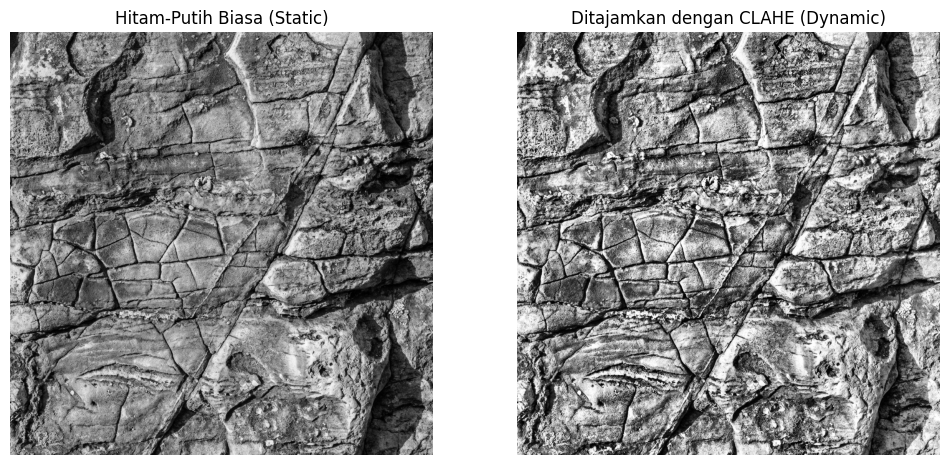

In [4]:
# 1. Mengubah gambar asli menjadi hitam-putih (Grayscale)
gambar_gray = cv2.cvtColor(gambar_asli, cv2.COLOR_BGR2GRAY)

# 2. Membuat "tukang penajam kontras" bernama CLAHE
clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))

# 3. Mengaplikasikan CLAHE ke gambar hitam-putih kita
gambar_clahe = clahe.apply(gambar_gray)

# 4. Menyiapkan 2 bingkai bersebelahan untuk membandingkan hasilnya
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Menempelkan gambar hitam-putih biasa di bingkai kiri
ax[0].imshow(gambar_gray, cmap='gray')
ax[0].set_title("Hitam-Putih Biasa (Static)")
ax[0].axis('off')

# Menempelkan gambar hasil CLAHE di bingkai kanan
ax[1].imshow(gambar_clahe, cmap='gray')
ax[1].set_title("Ditajamkan dengan CLAHE (Dynamic)")
ax[1].axis('off')

plt.show()

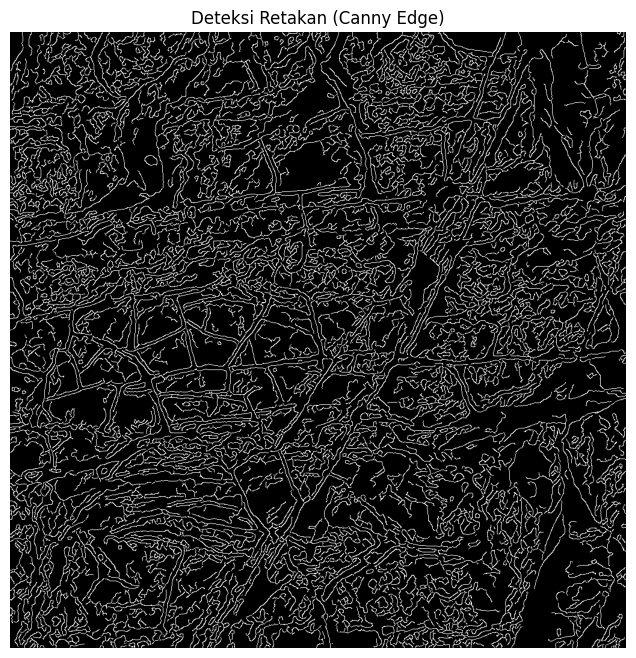

In [14]:
# 1. Menghaluskan gambar sedikit untuk membuang "noise" (bintik-bintik kotoran)
gambar_blur = cv2.GaussianBlur(gambar_clahe, (11, 11), 0)

# 2. Memanggil "tukang sketsa" bernama Canny untuk mencari dan menggambar retakan
garis_retakan = cv2.Canny(gambar_blur, threshold1=50, threshold2=150)

# 3. Menyiapkan bingkai untuk melihat hasil deteksi garis
plt.figure(figsize=(8, 8))
plt.imshow(garis_retakan, cmap='gray')
plt.title("Deteksi Retakan (Canny Edge)")
plt.axis('off')
plt.show()

Ditemukan 5 gambar untuk diproses.

Memproses gambar: batu5.jpg


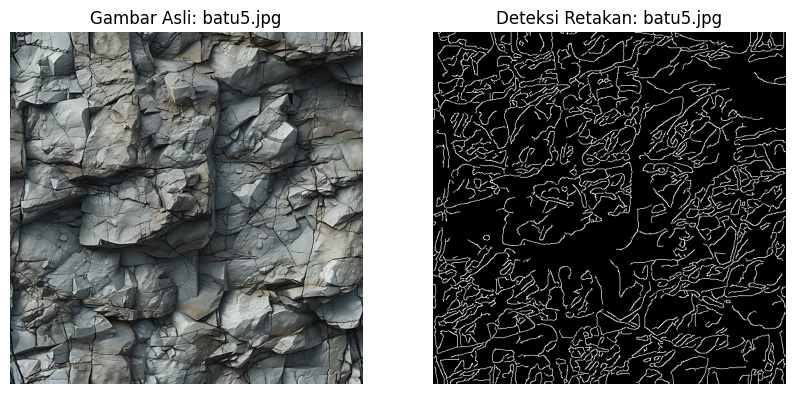


Memproses gambar: batu1.jpg


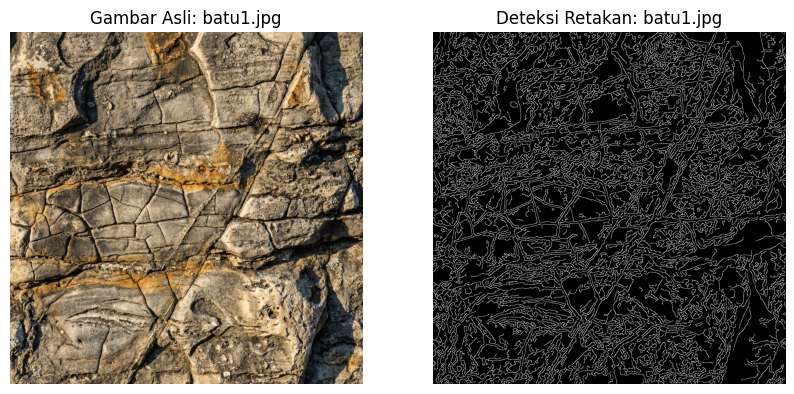


Memproses gambar: batu4.jpg


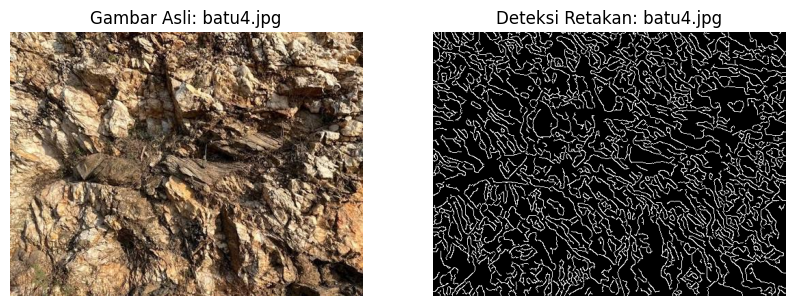


Memproses gambar: batu2.jpg


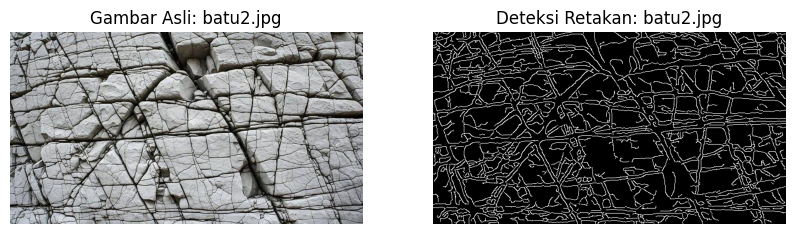


Memproses gambar: batu3.jpg


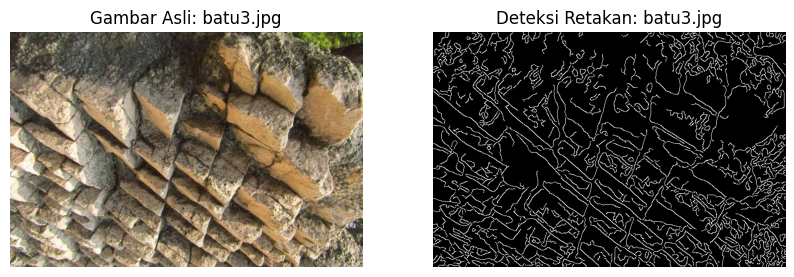


Semua gambar selesai diproses!


In [8]:
import os
import glob

# 1. Mencari semua file dengan akhiran .jpg di dalam folder saat ini
daftar_gambar = glob.glob('*.jpg')
print(f"Ditemukan {len(daftar_gambar)} gambar untuk diproses.")

# 2. Menggunakan for loop untuk memproses setiap gambar satu per satu
for nama_file in daftar_gambar:
    print(f"\nMemproses gambar: {nama_file}")

    # -- Proses yang sudah kita pelajari sebelumnya --
    # Membaca gambar
    img = cv2.imread(nama_file)

    # Mengubah ke grayscale
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Menajamkan kontras dengan CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_clahe = clahe.apply(img_gray)

    # Menghaluskan gambar dan mendeteksi garis retakan (gunakan parameter terbaikmu)
    img_blur = cv2.GaussianBlur(img_clahe, (11, 11), 0)
    img_canny = cv2.Canny(img_blur, threshold1=50, threshold2=150)

    # Menampilkan hasil berdampingan (Asli vs Deteksi Retakan)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    # Gambar asli (ubah ke RGB dulu untuk tampilan)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax[0].imshow(img_rgb)
    ax[0].set_title(f"Gambar Asli: {nama_file}")
    ax[0].axis('off')

    # Gambar hasil Canny
    ax[1].imshow(img_canny, cmap='gray')
    ax[1].set_title(f"Deteksi Retakan: {nama_file}")
    ax[1].axis('off')

    plt.show()
    # ------------------------------------------------

print("\nSemua gambar selesai diproses!")